# Planet Sandbox: Analysis-Ready PlanetScope (Pará, Brazil) via Sentinel Hub

**Why the earlier notebook failed (404):** this sandbox collection (`byoc-3f605f75-86c4-411a-b4ae-01c896f0e54e`, source `PS_ARD_SR_DAILY`) is hosted on **Sentinel Hub** (`services.sentinel-hub.com`), not on `api.planet.com`. Planet API keys only work with `api.planet.com`, and the `/data/collections/v2/...` path does not exist there.

**What this notebook does differently**
- Authenticates with an **OAuth client ID + secret** (not the API key).
- Searches with the Sentinel Hub **Catalog API**.
- Downloads a GeoTIFF with the **Process API**. There is no asset activation step.
- Then shows an RGB preview and NDVI.

**Before running (one time):**
1. Open the Planet Account app: <https://insights.planet.com/account/#/> → **OAuth Clients** → **Create New**.
2. Copy the **client ID** and **client secret** immediately (the secret is shown only once).
3. Your account needs Monitoring Credits (paid or trial). The sandbox data is CC-BY-NC.

The collection covers **2021-01-01 to 2023-12-29** over a 576 km² area centered near (-6.77, -52.38). Requests consume Processing Units from your account.

Never paste your secret into a shared notebook. It is requested with `getpass` below.

<!-- AUTO-DOCS -->
## Overview · 3 · NDVI analysis

> This notebook performs the analytical and interpretive work. Separating it from data discovery and preprocessing makes the workflow easier to test, explain, reproduce and reuse.

**What this notebook does**
- Calculate NDVI and NDVI change
- Classify moderate and strong decreases or increases
- Calculate area and percentage statistics
- Identify connected change patches
- Create graphs, maps and exports

**Expected inputs**
- `composites/composite_2021.tif`, `composite_2022.tif`, `composite_2023.tif`, `composite_All_years.tif` - 4-band float32 GeoTIFFs, EPSG:4326, about 10 m pixels

**Expected outputs**
- `composites/ndvi_statistics.csv` and the NDVI / change / patch figures shown in the notebook

Thresholds: |ΔNDVI| ≥ 0.10 = moderate and ≥ 0.20 = strong change, minimum patch ≈ 100 pixels (≈ 1 ha). The Streamlit app limits the thresholds to 0.10-0.20.

**Band order** of every GeoTIFF used here: 1 = Blue, 2 = Green, 3 = Red, 4 = NIR (a 5th band, `dataMask`, marks valid pixels in the per-date downloads). NDVI = (band 4 − band 3) / (band 4 + band 3).

*Credentials are never part of the notebook: they are typed at run time or read from environment variables.*

# 1. Import Satelite Imagery Composites [Run this cell after restarting the kernel]

In [18]:
from pathlib import Path

import numpy as np
import rasterio
import matplotlib.pyplot as plt

# Folder where the composite GeoTIFF files were saved
DATA_DIR = Path(
    "/Users/huss/data-processing/Github/"
    "TechnicalEvaluation-3-planet-dashboard-app-Solutions-Architect/"
    "Notebook/planet_downloads"
)

OUT_DIR = DATA_DIR.parent / "composites"

# File names created by the composite-generation code
composite_files = {
    "2021": OUT_DIR / "composite_2021.tif",
    "2022": OUT_DIR / "composite_2022.tif",
    "2023": OUT_DIR / "composite_2023.tif",
    "All years": OUT_DIR / "composite_All_years.tif",
}

composites = {}

for name, path in composite_files.items():
    if not path.exists():
        print("Missing:", path)
        continue

    with rasterio.open(path) as src:
        composites[name] = src.read().astype("float32")

        print(
            name,
            "loaded:",
            composites[name].shape,
            "CRS:",
            src.crs
        )

if "All years" not in composites:
    raise FileNotFoundError(
        "The all-years composite was not found. "
        "Run the composite-generation code once first."
    )

print("Loaded composites:", list(composites))


2021 loaded: (4, 2400, 2400) CRS: EPSG:4326
2022 loaded: (4, 2400, 2400) CRS: EPSG:4326
2023 loaded: (4, 2400, 2400) CRS: EPSG:4326
All years loaded: (4, 2400, 2400) CRS: EPSG:4326
Loaded composites: ['2021', '2022', '2023', 'All years']


## 2. Read the GeoTIFF

In [19]:
from pathlib import Path

import numpy as np
import rasterio


DATA_DIR = Path(
    "/Users/huss/data-processing/Github/"
    "TechnicalEvaluation-3-planet-dashboard-app-Solutions-Architect/"
    "Notebook/planet_downloads"
)

OUT_DIR = DATA_DIR.parent / "composites"

composite_files = {
    "2021": OUT_DIR / "composite_2021.tif",
    "2022": OUT_DIR / "composite_2022.tif",
    "2023": OUT_DIR / "composite_2023.tif",
    "All years": OUT_DIR / "composite_All_years.tif",
}


def print_geotiff_information(name, path):
    print("=" * 70)
    print(f"Composite: {name}")
    print(f"File: {path}")

    if not path.exists():
        print("Status: MISSING")
        return

    with rasterio.open(path) as src:
        # Read all raster bands
        image = src.read()

        print("Driver:", src.driver)
        print("Width:", src.width)
        print("Height:", src.height)
        print("Bands:", src.count)
        print("Array shape:", image.shape)
        print("CRS:", src.crs)
        print("Bounds:", src.bounds)
        print("Resolution:", src.res)
        print("Transform:", src.transform)
        print("Data types:", src.dtypes)
        print("NoData value:", src.nodata)
        print("Coordinate units:", src.crs.linear_units if src.crs else None)

        # GeoTIFF metadata
        print("Profile:")
        for key, value in src.profile.items():
            print(f"  {key}: {value}")

        print("Dataset tags:", src.tags())

        # Band-specific information
        print("Band descriptions:", src.descriptions)
        print("Band color interpretations:", src.colorinterp)

        # Use the GeoTIFF's valid-data mask
        valid_mask = src.dataset_mask() > 0
        valid_percentage = valid_mask.mean()

        print("Valid pixels:", f"{valid_percentage:.1%}")
        print("Invalid pixels:", f"{1 - valid_percentage:.1%}")

        # Statistics for each band
        print("Band statistics:")

        for band_number in range(1, src.count + 1):
            band = image[band_number - 1].astype("float32")

            # Apply the dataset mask
            valid_values = band[valid_mask]

            # Remove NaN and infinity values
            valid_values = valid_values[np.isfinite(valid_values)]

            if valid_values.size == 0:
                print(f"  Band {band_number}: no valid values")
                continue

            print(
                f"  Band {band_number}: "
                f"min={valid_values.min():.4f}, "
                f"max={valid_values.max():.4f}, "
                f"mean={valid_values.mean():.4f}, "
                f"median={np.median(valid_values):.4f}, "
                f"std={valid_values.std():.4f}"
            )


for name, path in composite_files.items():
    print_geotiff_information(name, path)


Composite: 2021
File: /Users/huss/data-processing/Github/TechnicalEvaluation-3-planet-dashboard-app-Solutions-Architect/Notebook/composites/composite_2021.tif
Driver: GTiff
Width: 2400
Height: 2400
Bands: 4
Array shape: (4, 2400, 2400)
CRS: EPSG:4326
Bounds: BoundingBox(left=-52.4825, bottom=-6.8735, right=-52.26725, top=-6.65775)
Resolution: (8.968750000000192e-05, 8.989583333333328e-05)
Transform: | 0.00, 0.00,-52.48|
| 0.00,-0.00,-6.66|
| 0.00, 0.00, 1.00|
Data types: ('float32', 'float32', 'float32', 'float32')
NoData value: nan
Coordinate units: unknown
Profile:
  driver: GTiff
  dtype: float32
  nodata: nan
  width: 2400
  height: 2400
  count: 4
  crs: EPSG:4326
  transform: | 0.00, 0.00,-52.48|
| 0.00,-0.00,-6.66|
| 0.00, 0.00, 1.00|
  blockxsize: 2400
  blockysize: 8
  tiled: False
  compress: deflate
  interleave: pixel
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band descriptions: (None, None, None, None)
Band color interpretations: (<ColorInterp.gray: 1>, <ColorInterp.undefined

In [20]:
# Test if composites contain dataMask

with rasterio.open(path) as src:
    image = src.read()

    print("Band descriptions:", src.descriptions)

    band_names = list(src.descriptions)

    if "dataMask" in band_names:
        data_mask_index = band_names.index("dataMask")
        valid = image[data_mask_index] > 0

        print("Valid pixels:", f"{valid.mean():.1%}")
    else:
        print("No dataMask band found.")
        valid = src.dataset_mask() > 0


Band descriptions: (None, None, None, None)
No dataMask band found.


In [21]:
import pandas as pd
import rasterio


summary = []

for name, path in composite_files.items():
    if not path.exists():
        summary.append({
            "composite": name,
            "file": str(path),
            "status": "missing",
        })
        continue

    with rasterio.open(path) as src:
        valid_mask = src.dataset_mask() > 0

        summary.append({
            "composite": name,
            "file": str(path),
            "status": "loaded",
            "width": src.width,
            "height": src.height,
            "bands": src.count,
            "crs": str(src.crs),
            "min_x": src.bounds.left,
            "min_y": src.bounds.bottom,
            "max_x": src.bounds.right,
            "max_y": src.bounds.top,
            "pixel_width": src.res[0],
            "pixel_height": src.res[1],
            "dtype": str(src.dtypes),
            "nodata": src.nodata,
            "valid_pixels_percent": valid_mask.mean() * 100,
        })


summary_df = pd.DataFrame(summary)

display(summary_df)


,composite,file,status,width,height,bands,crs,min_x,min_y,max_x,max_y,pixel_width,pixel_height,dtype,nodata,valid_pixels_percent
0,2021,/Users/huss/data-processing/Github/TechnicalEv...,loaded,2400,2400,4,EPSG:4326,-52.4825,-6.8735,-52.26725,-6.65775,0.00009,0.00009,"('float32', 'float32', 'float32', 'float32')",NaN,99.990278
1,2022,/Users/huss/data-processing/Github/TechnicalEv...,loaded,2400,2400,4,EPSG:4326,-52.4825,-6.8735,-52.26725,-6.65775,0.00009,0.00009,"('float32', 'float32', 'float32', 'float32')",NaN,99.990278
2,2023,/Users/huss/data-processing/Github/TechnicalEv...,loaded,2400,2400,4,EPSG:4326,-52.4825,-6.8735,-52.26725,-6.65775,0.00009,0.00009,"('float32', 'float32', 'float32', 'float32')",NaN,99.990278
3,All years,/Users/huss/data-processing/Github/TechnicalEv...,loaded,2400,2400,4,EPSG:4326,-52.4825,-6.8735,-52.26725,-6.65775,0.00009,0.00009,"('float32', 'float32', 'float32', 'float32')",NaN,99.990278


## 3. Display the image (true color)

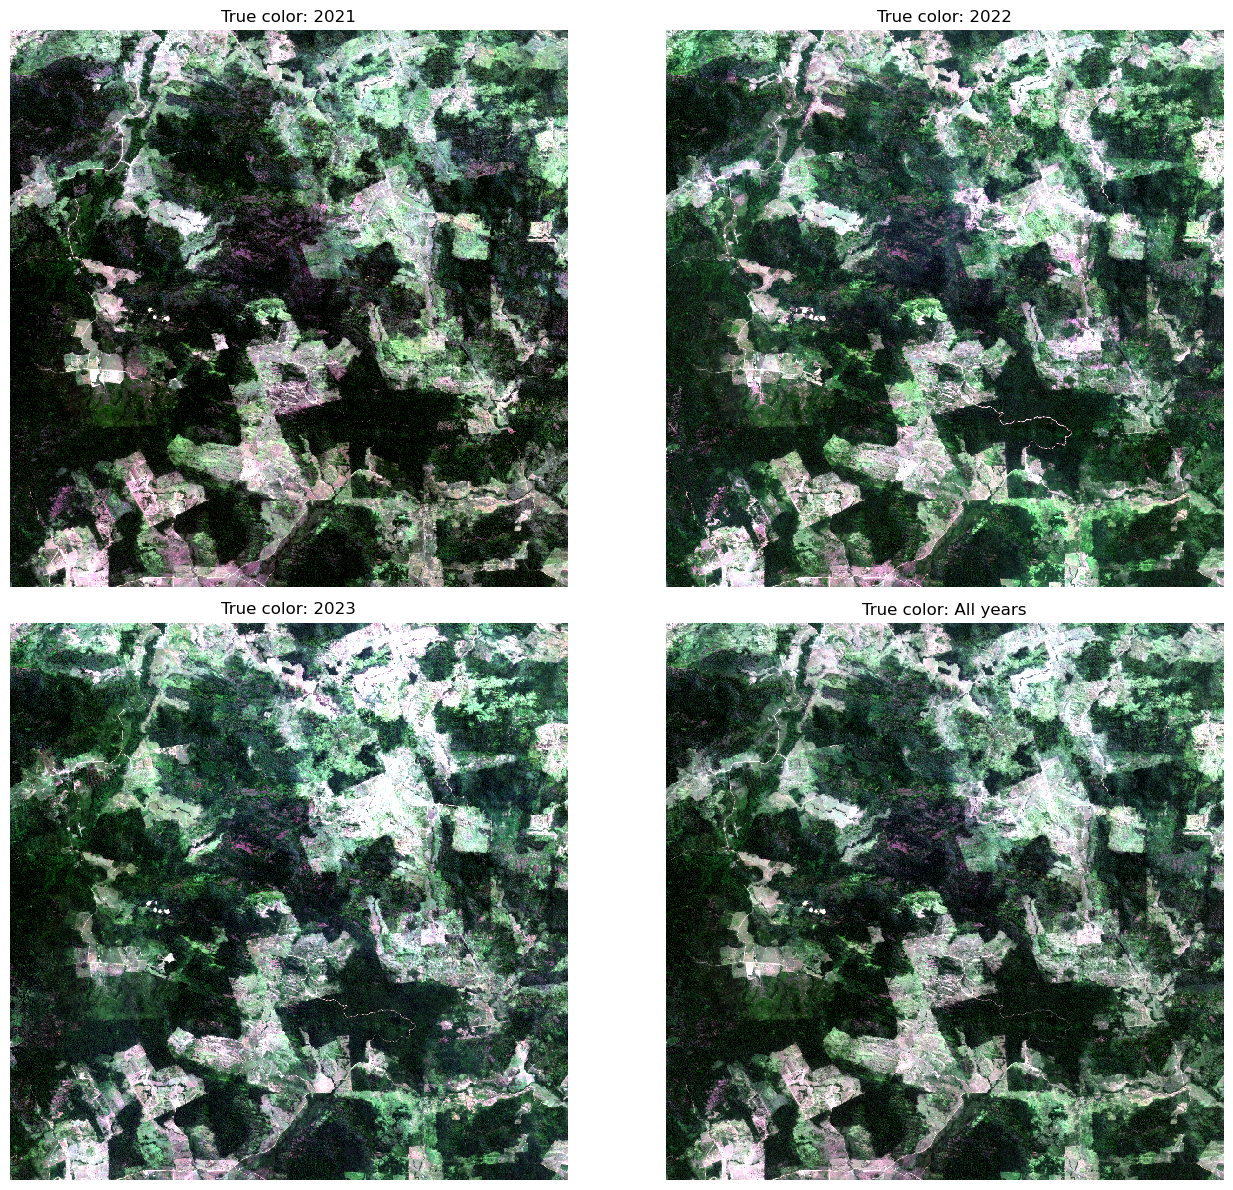

In [22]:
import numpy as np
import matplotlib.pyplot as plt


# Use the all-years composite as the reference image
ref = composites["All years"]

# Check the image dimensions
height, width = ref.shape[1], ref.shape[2]

# Downsample only for display
STEP = max(1, width // 1200)

# Calculate one contrast stretch for all panels
# Band order in the file is assumed to be:
# 0 = blue, 1 = green, 2 = red
lims = {}

for band_index in (0, 1, 2):
    values = ref[band_index]

    # Remove NaN and infinite values
    values = values[np.isfinite(values)]

    # Optional subsampling to make percentile calculation faster
    values = values[::10]

    if values.size == 0:
        raise ValueError(
            f"Band {band_index} contains no valid finite values."
        )

    low, high = np.percentile(values, [2, 98])

    # Avoid division by zero if a band is constant
    if high == low:
        high = low + 1e-6

    lims[band_index] = (low, high)


def to_rgb(array):
    """
    Convert a 3-band raster array into an RGB display array.

    Expected band order:
    band 0 = blue
    band 1 = green
    band 2 = red
    """

    rgb_channels = []

    # RGB display order: red, green, blue
    for band_index in (2, 1, 0):
        low, high = lims[band_index]

        band = array[band_index, ::STEP, ::STEP]

        scaled = (band - low) / (high - low)

        # Keep values between 0 and 1
        scaled = np.clip(scaled, 0, 1)

        # Replace NaN and infinity values
        scaled = np.nan_to_num(
            scaled,
            nan=0.0,
            posinf=1.0,
            neginf=0.0,
        )

        rgb_channels.append(scaled)

    return np.dstack(rgb_channels)


# Use a fixed order for the panels
names = ["2021", "2022", "2023", "All years"]

fig, axes = plt.subplots(
    nrows=2,
    ncols=2,
    figsize=(14, 12),
)

for ax, name in zip(axes.ravel(), names):
    if name not in composites:
        ax.set_title(f"{name}: missing")
        ax.axis("off")
        continue

    rgb_image = to_rgb(composites[name])

    ax.imshow(
        rgb_image,
        origin="upper",
        interpolation="nearest",
    )

    ax.set_title(f"True color: {name}")
    ax.axis("off")

plt.tight_layout()
plt.show()


## 4. NDVI
NDVI is a ratio, so it does not depend on whether the reflectance values are scaled (the documented ARPS scale is DN/10000).

Period        mean  median      p5     p95
2021         0.810   0.837   0.633   0.910
2022         0.806   0.844   0.616   0.897
2023         0.807   0.845   0.609   0.904
All years    0.810   0.842   0.639   0.903


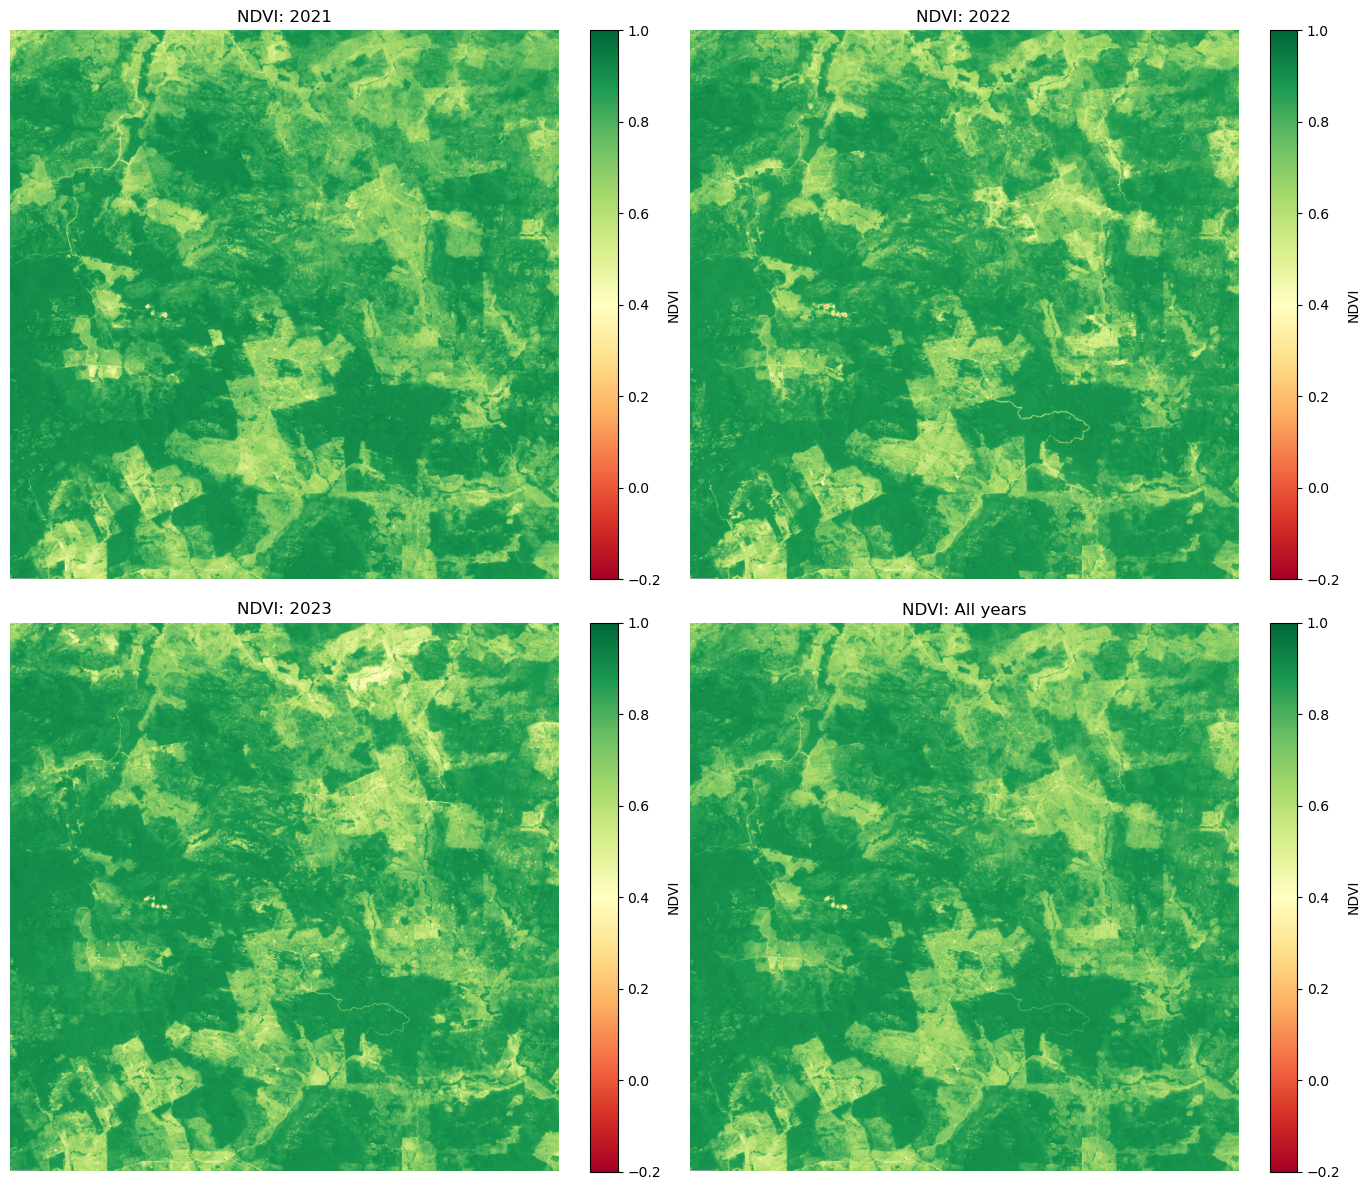

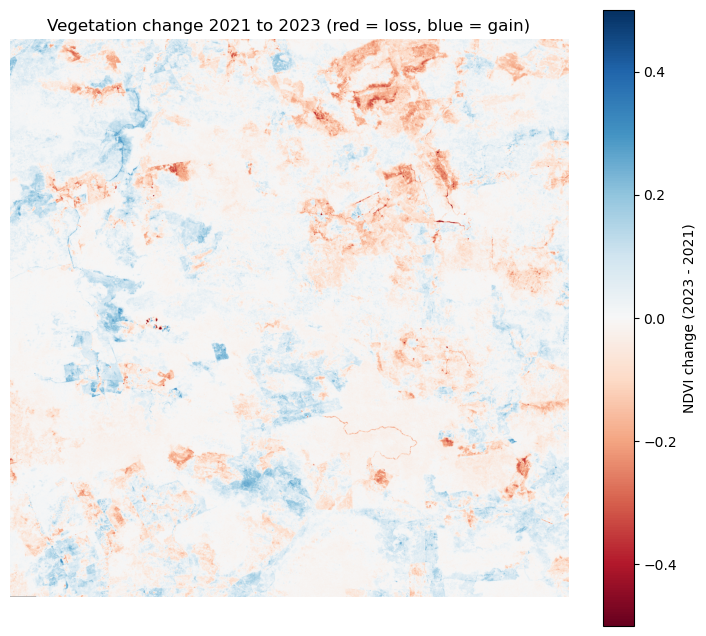

In [23]:
def ndvi_of(arr):
    red, nir = arr[2], arr[3]
    with np.errstate(divide="ignore", invalid="ignore"):
        return (nir - red) / (nir + red)

ndvis = {name: ndvi_of(arr) for name, arr in composites.items()}

print(f"{'Period':<10} {'mean':>7} {'median':>7} {'p5':>7} {'p95':>7}")
for name, nd in ndvis.items():
    v = nd[np.isfinite(nd)]
    print(f"{name:<10} {v.mean():7.3f} {np.median(v):7.3f} "
          f"{np.percentile(v, 5):7.3f} {np.percentile(v, 95):7.3f}")

fig, axes = plt.subplots(2, 2, figsize=(14, 12))
for ax, (name, nd) in zip(axes.ravel(), ndvis.items()):
    im = ax.imshow(nd[::STEP, ::STEP], cmap="RdYlGn", vmin=-0.2, vmax=1)
    ax.set_title(f"NDVI: {name}")
    ax.axis("off")
    fig.colorbar(im, ax=ax, fraction=0.046, label="NDVI")
for ax in axes.ravel()[len(ndvis):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# change map: last year minus first year
if "2021" in ndvis and "2023" in ndvis:
    diff = ndvis["2023"] - ndvis["2021"]
    plt.figure(figsize=(9, 8))
    plt.imshow(diff[::STEP, ::STEP], cmap="RdBu", vmin=-0.5, vmax=0.5)
    plt.colorbar(label="NDVI change (2023 - 2021)")
    plt.title("Vegetation change 2021 to 2023 (red = loss, blue = gain)")
    plt.axis("off")
    plt.show()

# Print NDVI statistics

In [24]:
statistics = []

for name, ndvi in ndvis.items():
    values = ndvi[np.isfinite(ndvi)]

    statistics.append(
        {
            "period": name,
            "valid_pixels": len(values),
            "mean_ndvi": np.mean(values),
            "median_ndvi": np.median(values),
            "p05_ndvi": np.percentile(values, 5),
            "p95_ndvi": np.percentile(values, 95),
        }
    )

statistics_df = pd.DataFrame(statistics)

print(statistics_df.round(3).to_string(index=False))

statistics_df.to_csv(
    OUT_DIR / "ndvi_statistics.csv",
    index=False,
)


   period  valid_pixels  mean_ndvi  median_ndvi  p05_ndvi  p95_ndvi
     2021       5759440      0.810        0.837     0.633     0.910
     2022       5759440      0.806        0.844     0.616     0.897
     2023       5759440      0.807        0.845     0.609     0.904
All years       5759440      0.810        0.842     0.639     0.903


3 9. Experimenting with visual/viasualization data

In [25]:
ndvi_2021 = ndvis["2021"]
ndvi_2023 = ndvis["2023"]

valid = (
    np.isfinite(ndvi_2021)
    & np.isfinite(ndvi_2023)
)

change = np.full_like(ndvi_2021, np.nan)
change[valid] = (
    ndvi_2023[valid]
    - ndvi_2021[valid]
)

loss_010 = valid & (change <= -0.10)
loss_020 = valid & (change <= -0.20)

print(
    "Pixels with NDVI decline >= 0.10:",
    loss_010.sum(),
    f"({loss_010.sum() / valid.sum():.2%})",
)

print(
    "Pixels with NDVI decline >= 0.20:",
    loss_020.sum(),
    f"({loss_020.sum() / valid.sum():.2%})",
)


Pixels with NDVI decline >= 0.10: 307956 (5.35%)
Pixels with NDVI decline >= 0.20: 44290 (0.77%)


# compares NDVI values from 2021 and 2023 to identify areas where vegetation declined

The code creates two maps:
•	The left map shows areas where NDVI declined by at least  0.10 .
•	The right map shows areas where NDVI declined by at least  0.20 .

Valid comparison pixels: 5759440
Decline >= 0.10: 307956 (5.35%)
Decline >= 0.20: 44290 (0.77%)


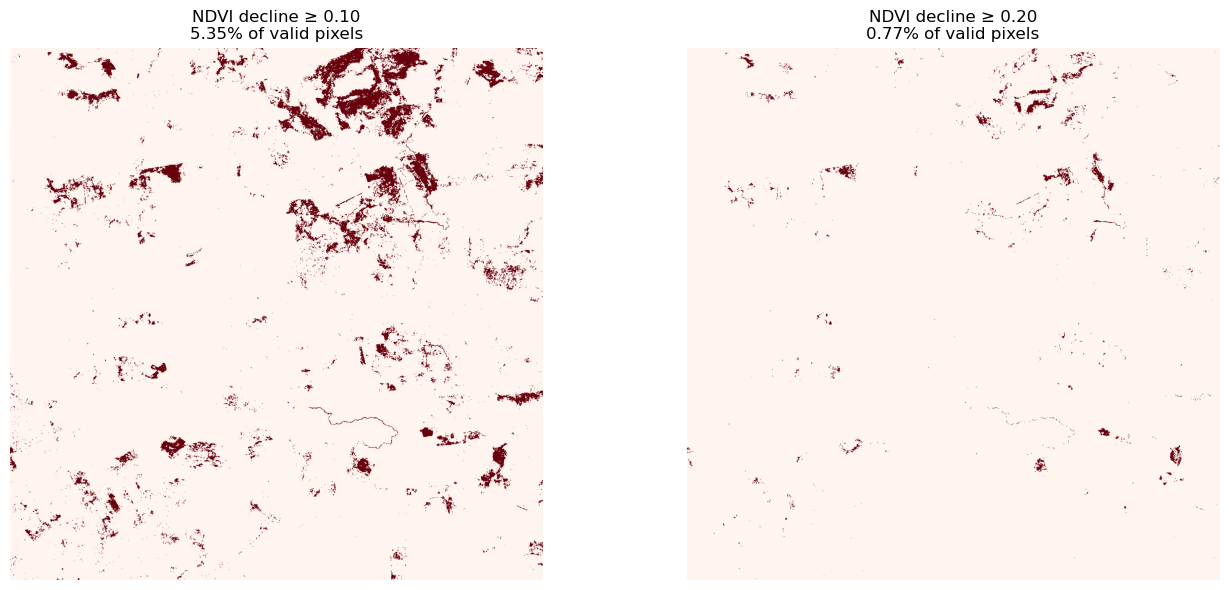

In [27]:
import numpy as np
import matplotlib.pyplot as plt


# Create validity masks from the NDVI arrays
valid_2021 = np.isfinite(ndvi_2021)
valid_2023 = np.isfinite(ndvi_2023)


# Check that the arrays have the same dimensions
if ndvi_2021.shape != ndvi_2023.shape:
    raise ValueError(
        f"Shape mismatch: "
        f"2021={ndvi_2021.shape}, "
        f"2023={ndvi_2023.shape}"
    )


# NDVI change:
# negative values = decline
# positive values = increase
ndvi_change = ndvi_2023 - ndvi_2021


# Only compare pixels valid in both years
valid_change = (
    valid_2021
    & valid_2023
)


# Decline thresholds
decline_010 = (
    valid_change
    & (ndvi_change <= -0.10)
)

decline_020 = (
    valid_change
    & (ndvi_change <= -0.20)
)


# Count valid pixels
valid_pixel_count = valid_change.sum()

if valid_pixel_count == 0:
    raise ValueError("There are no valid pixels for comparison.")


# Calculate counts and percentages
decline_010_count = decline_010.sum()
decline_020_count = decline_020.sum()

decline_010_percent = decline_010_count / valid_pixel_count
decline_020_percent = decline_020_count / valid_pixel_count


print("Valid comparison pixels:", valid_pixel_count)

print(
    "Decline >= 0.10:",
    decline_010_count,
    f"({decline_010_percent:.2%})",
)

print(
    "Decline >= 0.20:",
    decline_020_count,
    f"({decline_020_percent:.2%})",
)


# Display step
DISPLAY_STEP = max(1, ndvi_2021.shape[1] // 1200)


# Plot the results
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 6),
)


axes[0].imshow(
    decline_010[::DISPLAY_STEP, ::DISPLAY_STEP],
    cmap="Reds",
    vmin=0,
    vmax=1,
)

axes[0].set_title(
    f"NDVI decline ≥ 0.10\n"
    f"{decline_010_percent:.2%} of valid pixels"
)

axes[0].axis("off")


axes[1].imshow(
    decline_020[::DISPLAY_STEP, ::DISPLAY_STEP],
    cmap="Reds",
    vmin=0,
    vmax=1,
)

axes[1].set_title(
    f"NDVI decline ≥ 0.20\n"
    f"{decline_020_percent:.2%} of valid pixels"
)

axes[1].axis("off")


plt.tight_layout()
plt.show()


# 9. Total decline patches

What the boxes mean
Each yellow rectangle represents the smallest rectangular area containing one connected decline patch.
•	The red area is the cleaned NDVI-decline mask.
•	Each yellow rectangle surrounds one patch of at least 100 pixels.
•	The white number is the patch ID.
•	The rectangles may contain some pixels that are not part of the decline because they are bounding boxes, not exact patch boundaries.
 find_objects()  returns slices covering the minimal rectangular area around each labeled object.[scipy]
Show only the largest patches
If 55 rectangles are too many, show only the 10 largest

In [28]:
from scipy import ndimage

decline_020_clean = ndimage.binary_opening(
    decline_020,
    structure=np.ones((3, 3)),
)

decline_020_clean = ndimage.binary_closing(
    decline_020_clean,
    structure=np.ones((3, 3)),
)

labels, number_of_patches = ndimage.label(
    decline_020_clean
)

patch_sizes = np.bincount(
    labels.ravel()
)

patch_sizes = patch_sizes[1:]

large_patches = patch_sizes[
    patch_sizes >= 100
]

print(
    "Total decline patches:",
    number_of_patches,
)

print(
    "Patches with at least 100 pixels:",
    len(large_patches),
)

print(
    "Largest patch size:",
    patch_sizes.max()
    if len(patch_sizes)
    else 0,
    "pixels",
)


Total decline patches: 311
Patches with at least 100 pixels: 55
Largest patch size: 2433 pixels


In [4]:
# Find the bounding-box slices for each labeled patch
objects = ndimage.find_objects(labels)


fig, ax = plt.subplots(figsize=(12, 10))

# Display the cleaned decline mask
ax.imshow(
    decline_020_clean,
    cmap="Reds",
    vmin=0,
    vmax=1,
    origin="upper",
)


# Draw boxes around large patches
for patch_id in large_patch_ids:

    patch_slice = objects[patch_id - 1]

    if patch_slice is None:
        continue

    row_slice, col_slice = patch_slice

    row_start = row_slice.start
    row_stop = row_slice.stop
    col_start = col_slice.start
    col_stop = col_slice.stop

    rectangle = Rectangle(
        (col_start, row_start),
        col_stop - col_start,
        row_stop - row_start,
        fill=False,
        edgecolor="yellow",
        linewidth=1.5,
    )

    ax.add_patch(rectangle)

    ax.text(
        col_start,
        row_start,
        f"ID {patch_id}\n"
        f"{patch_sizes[patch_id - 1]} px",
        color="white",
        fontsize=8,
        backgroundcolor="black",
    )


ax.set_title(
    "NDVI decline ≥ 0.20 with large patch boxes"
)

ax.axis("off")
plt.tight_layout()
plt.show()


NameError: name 'labels' is not defined

## Interpretation

The NDVI change map identifies locations where vegetation conditions differed between the selected periods. Areas with negative change may indicate vegetation loss, but they may also result from seasonality, cloud contamination, fire, drought, flooding, harvest, or different acquisition dates. Results should therefore be interpreted as areas for investigation rather than confirmed deforestation.

## Limitations

- NDVI change is an indicator for investigation, not definitive proof of deforestation; the cause of a change is not identified.
- The compared scenes or annual composites may represent different seasons. A difference in NDVI may therefore reflect rainfall and seasonal vegetation dynamics rather than permanent land-cover change. For stronger conclusions, compare images from similar months, use multiple observations per year, and apply cloud and quality masks consistently.
- Each annual composite is built from a different set of acquisitions, so atmospheric, phenological and radiometric differences can leak into the change.
- Three annual points give a trajectory classification, not a statistically established trend.
- Image counts are scenes/tiles, not a measure of clear observations; a day can contain several scenes.
- Planet and Copernicus differ in sensor response, resolution, dates and processing; their NDVI values are comparable but not identical.
- Thresholds are analyst choices (limited here to 0.10-0.20); the reported area moves with them, see the sensitivity chart.
- Pixel areas use WGS-84 degree lengths per raster row (error well below 1 %).
- The sandbox data are licensed CC-BY-NC and cover 2021-01-01 to 2023-12-29.

## Future scope

- Compare images from the same months or seasons.
- Use monthly or quarterly time series instead of only annual composites.
- Add rainfall data.
- Add soil-moisture or soil-condition indicators.
- Add temperature and drought indicators.
- Add fire and burn-scar data.
- Add true-colour and false-colour composites.
- Add indices related to water, burn severity or vegetation stress.
- Add land-cover and protected-area layers.
- Compare results with official deforestation datasets (PRODES, DETER, MapBiomas).
- Add automated alerts for new change patches.
- Add confidence scores.
- Add field observations or validation points.
- Add cloud-probability and image-quality reporting.
- Add user-uploaded areas of interest.
- Add authenticated Planet API processing.
- Add scheduled data updates.
- Add historical time-series charts.
- Add automated PDF report generation on a schedule.
- Add a model to distinguish likely deforestation from seasonal or atmospheric effects.

*Each of these would require additional data, validation and processing time; none is implied by the current results.*